# RQ4: CR Evaluation Methods


In [2]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd
from itertools import product


In [3]:
INPUT_JSONL = "parsed_extracted_data.jsonl"

records = []
with open(INPUT_JSONL, "r", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

print(f"Loaded {len(records)} records")
print(records[0].keys())


Loaded 165 records
dict_keys(['Done ?', 'Who?', 'ID', 'Title', 'Authors', 'Venue type', 'Venue', 'Year', 'Task', 'Automation level', 'Model', 'Learning type', 'Model category', 'Model subcategory', 'Training method', 'Input features', 'Pre-processing techniques', 'Encoding techniques', 'Output', 'Dataset availability', 'Dataset', 'Dataset size', 'Language', 'Evaluation type', 'Evaluation method', 'Metrics', 'Baseline', 'Replication package', 'Challenges', 'Remarks', 'Task_Categories'])


In [4]:
df = pd.DataFrame(records)


In [5]:
df.iloc[157]


Done ?                                                                     1.0
Who?                                                                   Oussama
ID                                                                        P158
Title                        Intention is All You Need: Refining Your Code ...
Authors                      [Qi Guo, Xiaofei Xie, Shangqing Liu, Ming Hu, ...
Venue type                                                               Arxiv
Venue                                                                     None
Year                                                                      2025
Task                                                         [Code refinement]
Automation level                                               fully automated
Model                                                [GPT, DeepSeek, CodeQwen]
Learning type                                                     [Generation]
Model category                                      

In [6]:
# Exact match search
target_title = "Review4Repair: Code review aided automatic program repairing"

matching_rows = df[df["Title"] == target_title]

# Print the row(s)
print(matching_rows)

# Get the row index (row number)
print("Row index:", matching_rows.index.tolist())


    Done ?     Who?   ID                                              Title  \
64     1.0  Oussama  P65  Review4Repair: Code review aided automatic pro...   

                                              Authors Venue type Venue  Year  \
64  [Faria Huq, Masum Hasan, Md Mahim Anjum Haque,...    Journal   IST  2022   

                 Task Automation level  ... Dataset size Language  \
64  [Code refinement]  fully automated  ...        58021   [Java]   

                Evaluation type  \
64  [Quantitative, Qualitative]   

                                Evaluation method  \
64  [Experimental, Manual assessment, User study]   

                                              Metrics Baseline  \
64  [accuracy@k, Readability, Commit time, Precision]      yes   

   Replication package                          Challenges  \
64           available  test and train overlapping data +    

                                              Remarks Task_Categories  
64  Code eval criteria = Correctn

In [7]:
df.at[99, "Evaluation method"].append("Manual assessment")

if isinstance(df.at[75, "Evaluation type"], list):
    df.at[75, "Evaluation type"] = [
        v for v in df.at[75, "Evaluation type"] if v != "Qualitative"
    ]


df.at[96, "Learning type"] = ["Classification"]

if "ROUGE-L" not in df.at[50, "Metrics"]:
    df.at[50, "Metrics"].append("ROUGE")

if "Perfect Match (PM)" not in df.at[53, "Metrics"]:
    df.at[53, "Metrics"].append("Perfect Match (PM)")

df.at[77, "Evaluation method"].append("Manual assessment")

if "BLEU" not in df.at[77, "Metrics"]:
    df.at[77, "Metrics"].append("BLEU")

df.at[143, "Metrics"] = [
    "Correctness" if v == "accuracy" else v for v in df.at[143, "Metrics"]
]
df.at[105, "Metrics"] = [
    "Correctness" if v == "accuracy" else v for v in df.at[105, "Metrics"]
]

df.at[83, "Evaluation method"] = [
    v for v in df.at[83, "Evaluation method"] if v != "Experimental"
]
df.at[83, "Metrics"] = [
    "Correctness" if v == "accuracy" else v for v in df.at[83, "Metrics"]
]

if "BLEU" not in df.at[113, "Metrics"]:
    df.at[113, "Metrics"].append("Clarity")

df.at[157, "Metrics"] = [v for v in df.at[157, "Metrics"] if v != "accuracy"]
df.at[157, "Metrics"] = [v for v in df.at[157, "Metrics"] if v != "Precision"]

df.at[64, "Metrics"] = [v for v in df.at[64, "Metrics"] if v != "Precision"]

df.at[105, "Metrics"] = [v for v in df.at[105, "Metrics"] if v != "Specificity"]


In [8]:
df["Task"].explode().unique()


array(['Issue/bug detection', 'Reviewer recommendation',
       'Pull request assessment', 'Sentiment analysis',
       'Issue type prediction', 'Comment evaluation',
       'Pull request prioritization', 'Comment recommendation',
       'Code refinement', 'Comment generation',
       'Code review gamification', 'Data curation'], dtype=object)

In [9]:
import re
import unicodedata
from typing import Optional, Dict, Set

# 1) Metrics to REMOVE entirely if they appear (raw, human-readable list)
REMOVE_METRICS_RAW = {
    "Custom metric",
    "Semantic equivalence",
    "Type",
    "Nature",
    "Information",
    "performance measure",
    "p-value",
    "Pearson Correlation Coefficient",
    "Percentage Improvement",
    "Perfect Prediction",
    "Number of Refactored Code Smells",
    "Number of Detected Code Smells",
    "Kendall’s Tau-b",
    "appreciation rate",
    "Editing",
}

# 2) Alias → CANONICAL metric name (raw, human-readable list)
ALIAS_TO_CANONICAL_RAW = {
    "F1 score": "F1-score",
    "accuracy": "Accuracy",
    "auroc": "AUC",
    "auc": "AUC",
    "TPR": "Recall",
    "MAE (mean abs error)": "MAE",
    "AUC_ROC": "AUC",
    "ROUGE-L": "ROUGE",
    "hit rate (Rate)": "Hit rate",
    "False Alarm Rate (FAR)": "FPR",
    "Mean entropy": "Entropy",
    "entropy": "Entropy",
    "specificity": "Specificity",
    "tnr": "Specificity",
    "Average Recall (AR)": "Recall",
    "success rate": "Accuracy",
    "Positive Predictive Value": "Precision",
    "SA (standard accuracy)": "Accuracy",
    "Changeset Safety Ratio (CSR)": "Changeset Safety Ratio (CSR)",  # fixed typo
    "G_mean": "G-mean",
    # Recommended: AUCPR is AUC-PR, not AUC-ROC
    "AUCPR": "AUC-PR",
    "Explanation Clarity": "Clarity",
    "Average Precision (AP)": "MAP",
    "secureBLEU": "BLEU",
}


def _basic_normalize(s: str) -> str:
    s = s.strip()
    s = unicodedata.normalize("NFKD", s)
    s = s.replace("–", "-").replace("—", "-")
    s = s.lower()

    # Remove bullets
    s = re.sub(r"^[\u2022\-\*\•]+\s*", "", s)

    # Normalize whitespace
    s = re.sub(r"\s+", " ", s)

    # Keep @k exactly (only remove spaces around '@' if present)
    s = re.sub(r"\s*@\s*", "@", s)

    # Normalize parentheses spacing
    s = s.replace(" (", "(").replace("( ", "(").replace(" )", ")").replace(") ", ")")

    return s


def _build_remove_set(raw_set: Set[str]) -> Set[str]:
    return {_basic_normalize(x) for x in raw_set if x and x.strip()}


def _build_alias_map(raw_map: Dict[str, str]) -> Dict[str, str]:
    out = {}
    for k, v in raw_map.items():
        nk = _basic_normalize(k)
        if nk:
            out[nk] = v  # keep canonical as provided (case-sensitive)
    return out


# Build normalized lookups ONCE
REMOVE_METRICS = _build_remove_set(REMOVE_METRICS_RAW)
ALIAS_TO_CANONICAL = _build_alias_map(ALIAS_TO_CANONICAL_RAW)


def normalize_metric(metric_raw: str) -> Optional[str]:
    """
    Returns canonical metric name, or None if it should be removed.
    Does NOT reshape @k metrics beyond removing whitespace around '@'.
    """
    if not metric_raw or not metric_raw.strip():
        return None

    m = _basic_normalize(metric_raw)

    # Remove exact remove-items
    if m in REMOVE_METRICS:
        return None

    # Remove label-like prefixes (e.g., "type: xxx", "nature: yyy")
    for x in REMOVE_METRICS:
        if m.startswith(x + ":"):
            return None

    # Apply alias mapping (exact match after normalization)
    if m in ALIAS_TO_CANONICAL:
        return ALIAS_TO_CANONICAL[m]

        # Otherwise: Title Case for readability
    # - keeps @k intact
    # - forces short acronyms (fnr, fpr, mrr, auc, map, etc.) to uppercase
    tokens = []
    for w in m.split(" "):
        if "@k" in w:
            tokens.append(w)
        elif re.fullmatch(r"[a-z]{2,5}", w):
            tokens.append(w.upper())
        else:
            tokens.append(w.capitalize())

    canon = " ".join(tokens)
    return canon


In [10]:
from typing import List, Dict, Optional

# 3) Canonical taxonomy buckets (using CANONICAL names)
METRIC_TAXONOMY_CANON = {
    "classification_metrics": {
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUC",
        "MCC",
        "FPR",
        "FNR",
        "Negative Predictive Value",
        "Specificity",
        "G-mean",
        "Changest Safety Ratio (CSR)",
        "FILES AT Risk(far)",
        "R-Rate",
        "Outdated RATE",
        "Blocking Success RATE",
        "Review Omission RATE",
    },
    "ranking_recommendation_metrics": {
        "MRR",
        "MAP",
        "NDCG",
        "precision@k",
        "recall@k",
        "f1@k",
        "accuracy@k",
        "Hit rate",
        "Overlap Ratio(o)",
        "cost-effectiveness(er@k%)",
        "pass@k",
    },
    "generation_quality_metrics": {
        "BLEU",
        "ROUGE",
        "METEOR",
        "SARI",
        "GLEU",
        "Exactmatch",
        "Bertscore",
        "Perplexity",
        "Entropy",
        "Dataflow match",
        "CodeBLEU",
        "Perfect Match(pm)",
        "Levenshtein Distance (Edit distance)",
        "EDIT Progress(ep)",
    },
    "regression_error_metrics": {
        "MAE",
        "RMSE ( root mean squared error )",
        "Mre(mean Relative Error)",
        "Relative Error Detection Rate (REDR)",
        "MMRE",
    },
    "human_assessment": {
        "Usefulness",
        "Readability",
        "conciseness",
        "Relevance",
        "Correctness",
        "Clarity",
        "Explainability",
        "Fairness",
        "Usability" "acceptance rate",
        "Applicability",
        "usability",
        "Actionability",
        "Expertise",
        "civility",
        "Completeness",
        "M-score",
        "Ih-score",
        "I-score",
        "Win-tie-loss RATIO",
    },
    "efficiency_cost_metrics": {
        "TIME",
        "Memory",
        "Commit TIME",
        "Inference TIME",
        "CORE Workload",
    },
}

# 4) Categorization function
def categorize_metric_canon(metric_canon: str) -> List[str]:
    """
    Return list of matched categories (multi-label safe).
    """
    cats = []
    for cat, canon_set in METRIC_TAXONOMY_CANON.items():
        if metric_canon in canon_set:
            cats.append(cat)
    return cats


# 5) Full pipeline for a list of raw metrics
def clean_and_categorize_metrics(raw_metrics: List[str]) -> List[Dict]:
    """
    Input: raw extracted strings from papers
    Output: list of dicts with raw, canonical, categories
    """
    out = []
    for raw in raw_metrics:
        canon = normalize_metric(raw)  # <-- from previous code
        if canon is None:
            continue

        cats = categorize_metric_canon(canon)
        out.append(
            {
                "raw": raw,
                "canonical": canon,
                "categories": cats if cats else ["unknown"],
            }
        )

    return out


# 6) Optional helpers: dedupe + summary counts
def dedupe_by_canonical(rows: List[Dict]) -> List[Dict]:
    seen = set()
    deduped = []
    for r in rows:
        key = r["canonical"]
        if key not in seen:
            seen.add(key)
            deduped.append(r)
    return deduped


def category_counts(rows: List[Dict]) -> Dict[str, int]:
    counts = {}
    for r in rows:
        for c in r["categories"]:
            counts[c] = counts.get(c, 0) + 1
    return counts


In [11]:
def normalize_metric_list(ms):
    out = []
    for m in ms:
        canon = normalize_metric(m)  # returns str or None
        if canon is not None:
            out.append(canon)
    return out


df["metric_canonical"] = df["Metrics"].apply(normalize_metric_list)


In [12]:
def aggregate_categories(metric_list):
    categories = set()

    for m in metric_list:
        cats = categorize_metric_canon(m)
        for c in cats:
            categories.add(c)

    return sorted(categories)


In [13]:
df["metric_category"] = df["metric_canonical"].apply(aggregate_categories)


In [14]:
df.iloc[164]["metric_canonical"]


['F1-score', 'Precision', 'Recall', 'BLEU', 'Relevance']

In [15]:
df.iloc[164]["metric_category"]


['classification_metrics', 'generation_quality_metrics', 'human_assessment']

In [16]:
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = (
    "browser"  # alternatives: "svg", "png" (need kaleido), "notebook" (needs nbformat)
)

task_color_map = {
    # Greens (same vibe, more separation)
    "Pull request assessment": "rgba(109, 135, 100, 1)",  # a bit cooler + brighter
    "Reviewer recommendation": "rgba(109, 135, 100, 0.80)",  # lighter / more yellow-green
    "Pull request prioritization": "rgba(109, 135, 100, 0.60)",  # darker / deeper green
    # Pinks (same vibe, more separation)
    "Issue/bug detection": "rgba(239, 86, 117, 1)",  # slightly more magenta
    "Comment recommendation": "rgba(239, 86, 117, 0.80)",  # lighter / softer pink
    "Issue type prediction": "rgba(239, 86, 117, 0.6)",  # deeper red-pink
    # Purples (same vibe, more separation)
    "Comment generation": "rgba(122, 81, 149, 1)",  # slightly deeper
    "Code refinement": "rgba(122, 81, 149, 0.80)",  # lighter lavender
    "Data curation": "rgba(122, 81, 149, 0.60)",  # darker purple
    # Oranges (same vibe, more separation)
    "Comment evaluation": "rgba(255, 166, 0, 1)",  # slightly deeper orange
    "Sentiment analysis": "rgba(255, 166, 0, 0.80)",  # lighter peach
    "Code review gamification": "rgba(255, 166, 0, 0.60)",  # darker orange
}


def build_cat_task_eval_sankey_taskcolored(
    df: pd.DataFrame,
    task_col: str = "Task",
    cat_col: str = "metric_category",
    eval_col: str = "Evaluation method",
    min_link_value: int = 1,
    set_fixed_x: bool = True,
    task_color_map: dict | None = None,
    fallback_color: str = "rgba(200,200,200,0.35)",
    max_list_items_per_cell: int = 50,  # safety guard to prevent blow-ups
):
    """
    Builds a 3-column Sankey:
      Category -> Task -> Evaluation method

    Key properties:
    - Fast (uses explode, avoids iterrows + nested loops).
    - Colors links by task (both Cat->Task and Task->Eval).
    - Colors task nodes by task_color_map; other nodes are neutral.
    - Safety guard: truncates overly long lists in any single cell.
    """

    if task_color_map is None:
        raise ValueError("You must provide a task_color_map dictionary.")

    def as_list(x):
        # Normalize values into lists (supports list, scalar, NaN).
        if isinstance(x, list):
            return [i for i in x if pd.notna(i)]
        if pd.isna(x):
            return []
        return [x]

    def normalize_list_col(series: pd.Series) -> pd.Series:
        out = series.apply(as_list)
        # Guard against a single cell having enormous lists
        out = out.apply(lambda lst: lst[:max_list_items_per_cell])
        return out

    # Normalize columns to list-of-items
    df2 = df.copy()
    df2[task_col] = normalize_list_col(df2[task_col])
    df2[cat_col] = normalize_list_col(df2[cat_col])
    df2[eval_col] = normalize_list_col(df2[eval_col])

    # Optional: drop rows that have nothing at all (speeds things up)
    df2 = df2[
        (df2[task_col].str.len() > 0)
        & ((df2[cat_col].str.len() > 0) | (df2[eval_col].str.len() > 0))
    ].copy()

    # Build Category -> Task links using explode (fast)
    ct = df2.explode(cat_col).explode(task_col)
    ct = ct[[cat_col, task_col]].dropna()
    ct.columns = ["source", "target"]
    ct["task_key"] = ct["target"]

    links_ct = (
        ct.groupby(["source", "target", "task_key"], dropna=False)
        .size()
        .reset_index(name="value")
    )
    links_ct = links_ct[links_ct["value"] >= min_link_value].copy()
    links_ct["color"] = links_ct["task_key"].map(
        lambda t: task_color_map.get(t, fallback_color)
    )

    # Build Task -> Evaluation links using explode (fast)
    te = df2.explode(task_col).explode(eval_col)
    te = te[[task_col, eval_col]].dropna()
    te.columns = ["source", "target"]
    te["task_key"] = te["source"]

    links_te = (
        te.groupby(["source", "target", "task_key"], dropna=False)
        .size()
        .reset_index(name="value")
    )
    links_te = links_te[links_te["value"] >= min_link_value].copy()
    links_te["color"] = links_te["task_key"].map(
        lambda t: task_color_map.get(t, fallback_color)
    )

    # Combine links
    links_all = pd.concat(
        [
            links_ct[["source", "target", "value", "color"]],
            links_te[["source", "target", "value", "color"]],
        ],
        ignore_index=True,
    )

    if links_all.empty:
        raise ValueError(
            "No links were created. Check your columns and min_link_value."
        )

    # Create node labels and index mapping
    labels = pd.unique(links_all[["source", "target"]].values.ravel("K"))
    idx = {lab: i for i, lab in enumerate(labels)}

    # Node colors: color tasks, neutral for others
    node_colors = [task_color_map.get(lab, "rgba(220,220,220,0.90)") for lab in labels]

    # Fixed X positions (Category | Task | Evaluation)
    node_x = None
    if set_fixed_x:
        all_categories = set(links_ct["source"])
        all_tasks = set(links_ct["target"]) | set(links_te["source"])
        all_evals = set(links_te["target"])

        node_x = []
        for lab in labels:
            if lab in all_categories:
                node_x.append(0.01)
            elif lab in all_tasks:
                node_x.append(0.50)
            elif lab in all_evals:
                node_x.append(0.99)
            else:
                node_x.append(0.50)

    # Build Sankey figure
    fig = go.Figure(
        go.Sankey(
            arrangement="snap",
            node=dict(
                label=labels.tolist(),
                pad=18,
                thickness=14,
                color=node_colors,
                line=dict(color="rgba(150,150,150,0.60)", width=0.6),
                x=node_x,
            ),
            link=dict(
                source=links_all["source"].map(idx).astype(int),
                target=links_all["target"].map(idx).astype(int),
                value=links_all["value"].astype(int),
                color=links_all["color"],
            ),
        )
    )

    fig.update_layout(
        title="",
        font_size=25,
        margin=dict(l=10, r=10, t=20, b=10),
    )

    return fig


# USAGE
# df must exist and contain columns:
# Example:

fig = build_cat_task_eval_sankey_taskcolored(
    df,
    task_color_map=task_color_map,
    min_link_value=1,
    set_fixed_x=True,
)
fig.show()


c:\Users\imenj\AppData\Local\Programs\Python\Python311\Lib\site-packages\kaleido\_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.




In [17]:
# fig = build_cat_task_eval_sankey_taskcolored(
# )



In [18]:
df["metric_category"][30]


['classification_metrics']

In [19]:
from collections import Counter

# Flatten the list column and count values
category_count = Counter(
    item
    for sublist in df["metric_category"]
    if isinstance(sublist, list)
    for item in sublist
)

print(category_count)


Counter({'classification_metrics': 103, 'generation_quality_metrics': 48, 'ranking_recommendation_metrics': 34, 'human_assessment': 20, 'efficiency_cost_metrics': 14, 'regression_error_metrics': 6})


In [20]:
ids = df[
    df["Task"].apply(lambda x: isinstance(x, list) and "Pull request assessment" in x)
    & df["metric_category"].apply(
        lambda x: isinstance(x, list) and "regression_error_metrics" in x
    )
]["ID"].tolist()

print(ids)


['P26', 'P74', 'P87', 'P89', 'P95']


In [21]:
df[df["ID"] == "P131"]["Title"]


130    Towards Efficient Fine-Tuning of Language Mode...
Name: Title, dtype: object

In [22]:
df.iloc[130]["metric_category"]


['classification_metrics',
 'efficiency_cost_metrics',
 'generation_quality_metrics',
 'human_assessment']

In [23]:
df[
    df["Title"]
    == "Towards Efficient Fine-Tuning of Language Models With Organizational Data for Automated Software Review"
]["metric_category"]


130    [classification_metrics, efficiency_cost_metri...
Name: metric_category, dtype: object

In [24]:
row_numbers = df[
    df["metric_category"].apply(
        lambda x: isinstance(x, list) and "classification_metrics" in x
    )
].index.tolist()

print(row_numbers)


[0, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 24, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 40, 41, 43, 44, 45, 48, 50, 51, 52, 55, 56, 57, 58, 59, 61, 62, 63, 66, 67, 69, 70, 71, 72, 74, 75, 77, 78, 79, 82, 86, 87, 89, 90, 92, 93, 94, 95, 96, 98, 100, 102, 103, 104, 106, 107, 113, 117, 120, 123, 125, 127, 128, 130, 131, 134, 135, 136, 138, 140, 142, 146, 147, 148, 149, 150, 151, 153, 155, 158, 159, 163, 164]


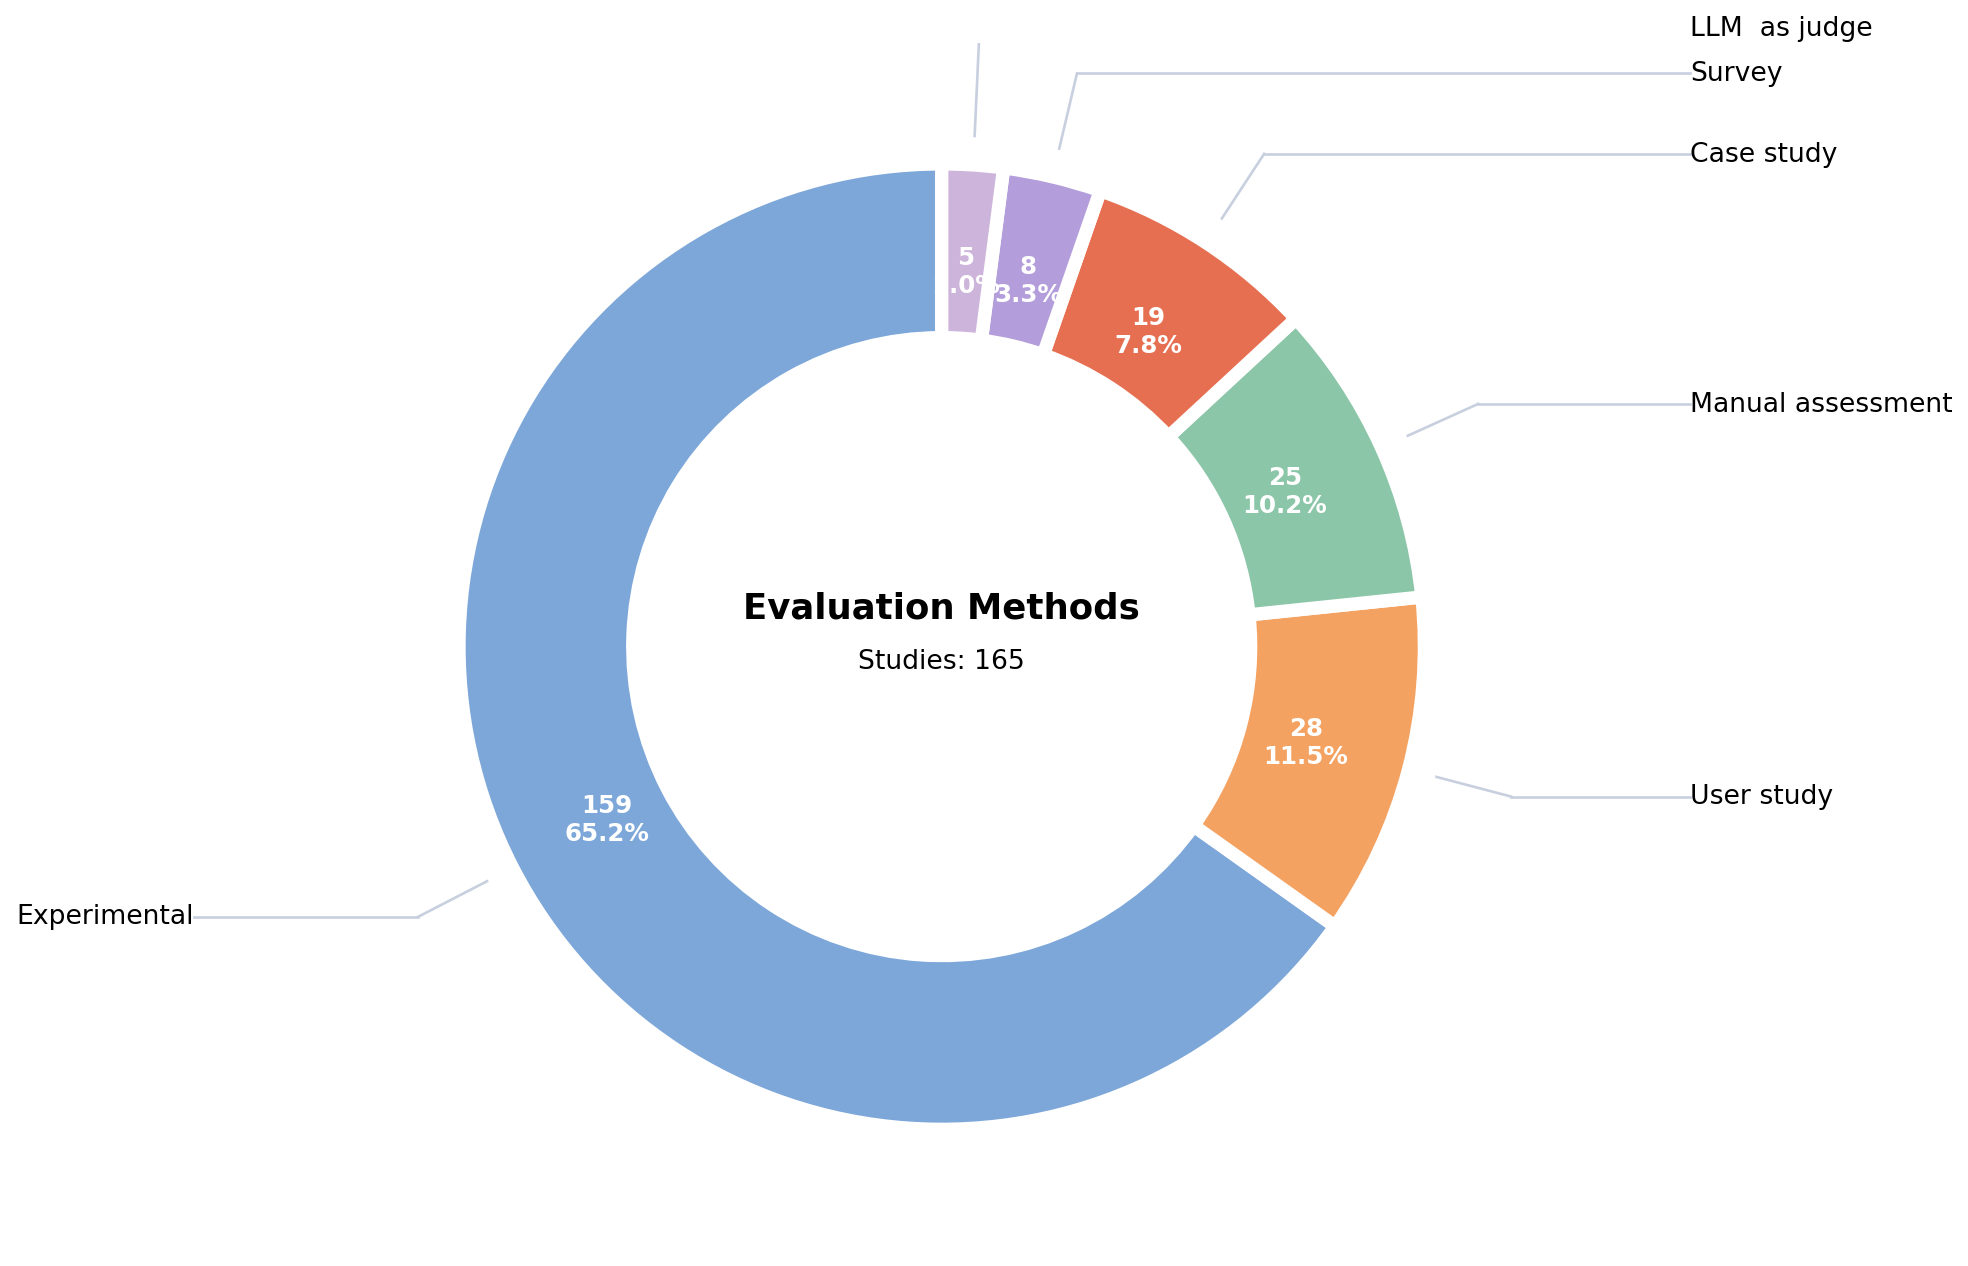

In [25]:
PASTEL_COLORS = [
    "#7DA7D9",  # pastel blue
    "#F4A261",  # pastel orange
    "#8BC6A8",  # pastel green
    "#E76F51",  # pastel red
    "#B39DDB",  # pastel purple
    "#CDB4DB",  # pastel lavender
    "#E9C46A",  # pastel yellow
    "#A8DADC",  # pastel cyan
]
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

COL = "Evaluation method"  # <-- change if needed

s = df[COL].explode().dropna()
s = s.astype(str).str.strip()
s = s[s != ""]

counts = s.value_counts()
labels = counts.index.to_list()
values = counts.values
total_uses = int(values.sum())
n_studies = int(df.shape[0])  # if each row = one study/paper

fig, ax = plt.subplots(figsize=(13, 8), dpi=160)
colors = PASTEL_COLORS[: len(values)]

wedges, _ = ax.pie(
    values,
    startangle=90,
    colors=colors,
    wedgeprops=dict(width=0.36, edgecolor="white", linewidth=6),
)


ax.text(
    0,
    0.08,
    "Evaluation Methods",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
)
ax.text(0, -0.03, f"Studies: {n_studies}", ha="center", va="center", fontsize=12)

for i, w in enumerate(wedges):
    ang = (w.theta2 + w.theta1) / 2.0
    x = np.cos(np.deg2rad(ang))
    y = np.sin(np.deg2rad(ang))
    pct = values[i] / total_uses * 100

    ax.text(
        0.78 * x,
        0.78 * y,
        f"{values[i]}\n{pct:.1f}%",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="white",
    )

# geometry controls (tune if you want)
r_line = 1.06  # line starts
r_elbow = 1.22  # elbow radius
x_text_right = 1.55
x_text_left = -1.55
min_sep = 0.09  # vertical separation between labels on same side

# compute midpoints
pts = []
for i, w in enumerate(wedges):
    ang = (w.theta2 + w.theta1) / 2.0
    x = np.cos(np.deg2rad(ang))
    y = np.sin(np.deg2rad(ang))
    side = "right" if x >= 0 else "left"
    pts.append({"i": i, "x": x, "y": y, "side": side, "label": labels[i]})

# separate sides
left = sorted([p for p in pts if p["side"] == "left"], key=lambda p: p["y"])
right = sorted([p for p in pts if p["side"] == "right"], key=lambda p: p["y"])


def spread(points):
    # spread upward to avoid overlaps
    for j in range(1, len(points)):
        if points[j]["y"] - points[j - 1]["y"] < min_sep:
            points[j]["y"] = points[j - 1]["y"] + min_sep
    # spread downward if needed (keep within bounds)
    for j in range(len(points) - 2, -1, -1):
        if points[j + 1]["y"] - points[j]["y"] < min_sep:
            points[j]["y"] = points[j + 1]["y"] - min_sep
    # clamp
    for p in points:
        p["y"] = max(min(p["y"], 1.05), -1.05)


spread(left)
spread(right)

# draw lines + text
def draw_side(points, x_text):
    for p in points:
        i = p["i"]
        # original direction for radial line
        w = wedges[i]
        ang = (w.theta2 + w.theta1) / 2.0
        x0 = np.cos(np.deg2rad(ang))
        y0 = np.sin(np.deg2rad(ang))

        # radial to elbow
        x1 = r_elbow * x0
        y1 = r_elbow * p["y"]  # adjusted y for label collision avoidance

        # line segments: radial then horizontal
        ax.plot([r_line * x0, x1], [r_line * y0, y1], color="#c8d0df", lw=1.2)
        ax.plot([x1, x_text], [y1, y1], color="#c8d0df", lw=1.2)

        ax.text(
            x_text,
            y1,
            p["label"],
            ha="left" if x_text > 0 else "right",
            va="center",
            fontsize=12,
        )


draw_side(left, x_text_left)
draw_side(right, x_text_right)

ax.set(aspect="equal")
ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-1.25, 1.25)
plt.tight_layout()
plt.show()


In [26]:
import pandas as pd

SUBCATEGORY_MAP = {
    # Classification metrics
    "Accuracy": "Basic performance",
    "Precision": "Basic performance",
    "Recall": "Basic performance",
    "F1-score": "Basic performance",
    "AUC": "Basic performance",
    "MCC": "Basic performance",
    "FPR": "Error & confusion-based",
    "FNR": "Error & confusion-based",
    "Negative Predictive Value": "Error & confusion-based",
    "Specificity": "Error & confusion-based",
    "G-mean": "Error & confusion-based",
    "Changest Safety Ratio (CSR)": "Task-specific",
    "FILES AT Risk(far)": "Task-specific",
    "R-Rate": "Task-specific",
    "Outdated RATE": "Task-specific",
    "Blocking Success RATE": "Task-specific",
    "Review Omission RATE": "Task-specific",
    # Ranking & recommendation metrics
    "MRR": "Ranking quality",
    "MAP": "Ranking quality",
    "NDCG": "Ranking quality",
    "precision@k": "Top-k variants",
    "recall@k": "Top-k variants",
    "f1@k": "Top-k variants",
    "accuracy@k": "Top-k variants",
    "Hit rate": "Coverage & effectiveness",
    "Overlap Ratio(o)": "Coverage & effectiveness",
    "cost-effectiveness(er@k%)": "Coverage & effectiveness",
    "pass@k": "Coverage & effectiveness",
    # Generation quality metrics
    "BLEU": "Lexical overlap",
    "ROUGE": "Lexical overlap",
    "METEOR": "Lexical overlap",
    "SARI": "Lexical overlap",
    "GLEU": "Lexical overlap",
    "Exactmatch": "Lexical overlap",
    "Levenshtein Distance (Edit distance)": "Lexical overlap",
    "EDIT Progress(ep)": "Lexical overlap",
    "Bertscore": "Semantic similarity",
    "CodeBLEU": "Code-aware",
    "Dataflow match": "Code-aware",
    "Perfect Match(pm)": "Code-aware",
    "Perplexity": "Uncertainty",
    "Entropy": "Uncertainty",
    # Regression / error metrics
    "MAE": "Absolute / squared error",
    "RMSE ( root mean squared error )": "Absolute / squared error",
    "Mre(mean Relative Error)": "Relative error",
    "Relative Error Detection Rate (REDR)": "Relative error",
    "MMRE": "Relative error",
    # Human assessment
    "Usefulness": "Perceived quality",
    "Readability": "Perceived quality",
    "conciseness": "Perceived quality",
    "Relevance": "Perceived quality",
    "Correctness": "Perceived quality",
    "Clarity": "Perceived quality",
    "Completeness": "Perceived quality",
    "acceptance rate": "User perception & interaction",
    "Applicability": "User perception & interaction",
    "Usability": "User perception & interaction",
    "usability": "User perception & interaction",
    "Actionability": "User perception & interaction",
    "Explainability": "User perception & interaction",
    "Fairness": "User perception & interaction",
    "Expertise": "Expert judgement",
    "civility": "Expert judgement",
    "M-score": "Expert judgement",
    "Ih-score": "Expert judgement",
    "I-score": "Expert judgement",
    "Win-tie-loss RATIO": "Expert judgement",
    # Efficiency & cost metrics
    "TIME": "Runtime",
    "Commit TIME": "Runtime",
    "Inference TIME": "Runtime",
    "Memory": "Resource usage",
    "CORE Workload": "Resource usage",
}


def is_missing_scalar(x):
    return x is None or (isinstance(x, float) and pd.isna(x))


def normalize_any(x):
    """
    Converts a scalar or list cell into canonical form.
    Uses normalize_metric if available.
    """
    if isinstance(x, list):
        out = []
        for item in x:
            if is_missing_scalar(item):
                continue
            if "normalize_metric" in globals():
                canon = normalize_metric(item)
            else:
                canon = str(item).strip()
            if canon is not None:
                out.append(canon)
        return out

    if is_missing_scalar(x):
        return None

    if "normalize_metric" in globals():
        return normalize_metric(x)
    return str(x).strip()


def subcategory_any(x):
    """
    Maps canonical metric(s) to UNIQUE subcategories (no duplicates).
    """
    if isinstance(x, list):
        subcats = [SUBCATEGORY_MAP.get(str(item).strip(), "unknown") for item in x]
        return list(set(subcats))  # remove duplicates

    if x is None:
        return "unknown"

    return SUBCATEGORY_MAP.get(str(x).strip(), "unknown")


# Try to detect metric column automatically
candidate_cols = [
    "canonical",
    "metric",
    "Metric",
    "metrics",
    "Metrics",
    "raw",
    "Raw",
    "metric_canon",
]

metric_col = None
for col in candidate_cols:
    if col in df.columns:
        metric_col = col
        break

if metric_col is None:
    raise ValueError(
        f"Could not find a metric column. Available columns: {list(df.columns)}"
    )

# Create canonical only if it does not already exist
if "canonical" not in df.columns:
    df["canonical"] = df[metric_col].apply(normalize_any)

# Create subcategory
df["subcategory"] = df["canonical"].apply(subcategory_any)

# Preview
print("Using metric column:", metric_col)
print(df[["canonical", "subcategory"]].head(20))


Using metric column: Metrics
                                            canonical  \
0                                [Accuracy, FNR, FPR]   
1                                   [accuracy@k, MRR]   
2                               [Entropy, Perplexity]   
3                        [FPR, Recall, F1-score, AUC]   
4                       [Precision, Recall, F1-score]   
5                                                  []   
6             [Accuracy, Precision, Recall, F1-score]   
7   [Precision, Accuracy, Recall, Precision, Negat...   
8                       [Precision, Recall, F1-score]   
9                                 [Precision, Recall]   
10            [Precision, Recall, Accuracy, F1-score]   
11                                [Precision, Recall]   
12         [AUC, cost-effectiveness(er@k%), F1-score]   
13                              [Precision, Accuracy]   
14                               [AUC, MRR, recall@k]   
15                                        [Precision]   
16

In [27]:
df.iloc[0]["Metrics"]


['accuracy', 'FNR', 'FPR']

In [28]:
df.iloc[0]["subcategory"]


['Error & confusion-based', 'Basic performance']

In [39]:
# Filter rows where "Resource usage" is in subcategory
mask = df["subcategory"].apply(
    lambda x: "Resource usage" in x if isinstance(x, list) else x == "Resource usage"
)

# Replace "Paper" with your actual ID column name if different
paper_ids = df.loc[mask, "ID"].dropna().unique().tolist()

print(paper_ids)


['P61', 'P88']
